# Volume Summary

**Goal:** estimate how many original tweets were about each issue each week in the full dataset.

**Why we need this:** we're only using a small sample from the dataset, so we may not be able to tell
how much the political issues we're studying are being discussed. This helps answer the question: "Is 
your model spotting a new way of talking, or just noticing that more people are talking?" Volume measures how loud a conversation is. The topic features (`shift_score`, `topic_*`) measure what is being said. In the ablation study, we train one model on volume features only and another that also includes the topic features. If the second model scores higher, the topic features tells us more information besides volume.

**Inputs**
- `DataFiles/tk_issue_week_features.csv`: Unsupervised issue-week table
- `weekly_orig_totals.csv`: Count of all original English tweets per week from the full dataset

**Outputs**
- `DataFiles/volume_summary.csv`: one row per issue-week with the volume columns
- `DataFiles/features_with_volume.csv`: Unsupervised table with the volume columns added (ready for the supervised pipeline)

**Main formula:** `orig_tweet_count = weekly_orig_total × issue_share`

In [ ]:
import numpy as np                
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

In [ ]:
# ---- File paths ----
# These paths assume this notebook sits one folder below the repo's top level
# (for example in supervised/ or Notebooks/). Change them if yours is elsewhere.
FEATURES_PATH = "../DataFiles/tk_issue_week_features.csv"
TOTALS_PATH   = "../weekly_orig_totals.csv"

VOLUME_OUT    = "../DataFiles/volume_summary.csv"
FEATURES_OUT  = "../DataFiles/features_with_volume.csv"

#### Load issue-week table
Each row is one issue-week (one issue in one week). The columns we need for volume:
- issue_share: the issue's share of that week's sample (n_tweets_issue / n_tweets_week)
- days_with_data: how many days of tweets that week has (some weeks have tweets on fewer than 7 days)

In [ ]:
features = pd.read_csv(FEATURES_PATH)

print("Rows, columns:", features.shape)
print("Issues:", sorted(features["issue"].unique()))
print("Weeks:", features["week"].min(), "to", features["week"].max())
features[["week", "issue", "n_tweets_issue", "n_tweets_week", "days_with_data", "issue_share"]].head()

Rows, columns: (155, 20)
Issues: ['abortion', 'democracy', 'economy', 'foreign_policy', 'immigration']
Weeks: 0 to 30


,week,issue,n_tweets_issue,n_tweets_week,days_with_data,issue_share
0,0,abortion,121,14985,7,0.008075
1,1,abortion,126,14991,7,0.008405
2,2,abortion,64,14980,7,0.004272
3,3,abortion,62,14990,7,0.004136
4,4,abortion,66,14990,7,0.004403


#### Load weekly totals from the full dataset

In [ ]:
totals = pd.read_csv(TOTALS_PATH)
print("Columns in the raw file:", totals.columns.tolist())

totals = totals[["week", "weekly_orig_total"]]

# Check to make sure there's one row per week.
# If a week appears twice the join would double the rows for that week.
assert totals["week"].is_unique, "A week appears more than once in the totals file."

print("Weeks in totals file:", len(totals))
totals.head()

Columns in the raw file: ['Unnamed: 0.1', 'Unnamed: 0', 'week', 'weekly_orig_total', 'chunk_sample']
Weeks in totals file: 31


,week,weekly_orig_total
0,0,654419
1,1,919812
2,2,365423
3,3,539144
4,4,218530


In [ ]:
# Check that both files cover the same weeks before joining them.
weeks_in_features = set(features["week"])
weeks_in_totals   = set(totals["week"])

print("Weeks missing from totals:  ", sorted(weeks_in_features - weeks_in_totals))
print("Extra weeks only in totals: ", sorted(weeks_in_totals - weeks_in_features))

Weeks missing from totals:   []
Extra weeks only in totals:  []


#### Join the two tables on week

In [ ]:
vol = features.merge(totals, on="week", how="left", validate="many_to_one")

# The join should not add or remove rows.
assert len(vol) == len(features), "Row count changed during the join"
# Every row should have found its week's total.
assert vol["weekly_orig_total"].notna().all(), "Some weeks have no weekly_orig_total"

print("Rows after join:", len(vol))

Rows after join: 155


#### Estimate each issue's original volume before sampling
orig_tweet_count = weekly_orig_total × issue_share

Example: if a week has 1,000,000 original tweets in the full dataset and abortion is 0.8% of that week's sample, we estimate about 8,000 abortion tweets that week.

This works because the sample takes about 15,000 original tweets from each week, drawn at the same rate from every chunk file in that week, so each week's sample reflects the whole week. Issues with few sample tweets, like abortion that has about 60–120 per week, have less precise estimates.

In [ ]:
vol["orig_tweet_count"] = (vol["weekly_orig_total"] * vol["issue_share"]).round().astype(int)

vol[["week", "issue", "weekly_orig_total", "issue_share", "orig_tweet_count"]].head(10)

,week,issue,weekly_orig_total,issue_share,orig_tweet_count
0,0,abortion,654419,0.008075,5284
1,1,abortion,919812,0.008405,7731
2,2,abortion,365423,0.004272,1561
3,3,abortion,539144,0.004136,2230
4,4,abortion,218530,0.004403,962
5,5,abortion,809682,0.005141,4163
6,6,abortion,2242658,0.007921,17765
7,7,abortion,1111350,0.007468,8299
8,8,abortion,478320,0.008656,4140
9,9,abortion,2037974,0.009218,18786


## Fix partial weeks with per-day volume
Some weeks are missing days of data. A week with only 2 days of tweets can look quiet even if people were posting just as much, which could be a gap in data collection instead of a drop in posting.

We'll divide by days_with_data to get an average per day. days_with_data counts the dates that appear in our sample, not in the full dataset.
- `weekly_orig_per_day`: all original tweets per day that week (all issues together)
- `orig_per_day`: this issue's estimated tweets per day

In [ ]:
# Show every week that has fewer than 7 days of data
partial_weeks = (vol[["week", "days_with_data", "weekly_orig_total"]]
                 .drop_duplicates()
                 .query("days_with_data < 7"))
print("Weeks with fewer than 7 days of data:")
print(partial_weeks.to_string(index=False))

# Per-day versions
vol["weekly_orig_per_day"] = vol["weekly_orig_total"] / vol["days_with_data"]
vol["orig_per_day"]        = vol["orig_tweet_count"]  / vol["days_with_data"]

Weeks with fewer than 7 days of data:
 week  days_with_data  weekly_orig_total
   11               6            3488880
   12               3             670668
   13               2              95343
   16               2             330558
   17               3             146312
   18               5             216724
   19               4             693151
   28               6            1490406
   30               4             890741


#### Log scale and week-to-week change
**Log scale:** Busy issue-weeks have thousands of tweets per day and quiet ones have a few hundred. A log transform shrinks big numbers more than small ones, so a few giant weeks don't dominate. This mainly helps linear models (Logistic Regression, SVM) that treat each step in a number as equally important. Tree models (Gradient-Boosted Trees) don't care much either way. We use `np.log1p`, which is log(1 + x), so a value of 0 doesn't break the math.

**Change from last week:** a sudden jump in attention may say more than raw size. Subtracting last week's log from this week's log gives the change. A change of +0.69 means volume roughly doubled; −0.69 means it roughly halved. We compute it within each issue, in week order, and on the per-day numbers so partial weeks don't create fake drops. Each issue's first week has no "last week," so it stays blank (NaN, "not a number").

In [ ]:
vol["log_orig_per_day"] = np.log1p(vol["orig_per_day"])

# Sort so that "the previous row" really is last week for the same issue
vol = vol.sort_values(["issue", "week"]).reset_index(drop=True)

# diff() = this row minus the row before it, done separately for each issue
vol["log_orig_per_day_change"] = vol.groupby("issue")["log_orig_per_day"].diff()

vol[["issue", "week", "days_with_data", "orig_tweet_count",
     "orig_per_day", "log_orig_per_day", "log_orig_per_day_change"]].head(8)

,issue,week,days_with_data,orig_tweet_count,orig_per_day,log_orig_per_day,log_orig_per_day_change
0,abortion,0,7,5284,754.857143,6.627852,NaN
1,abortion,1,7,7731,1104.428571,7.007988,0.380136
2,abortion,2,7,1561,223.000000,5.411646,-1.596342
3,abortion,3,7,2230,318.571429,5.766981,0.355335
4,abortion,4,7,962,137.428571,4.930354,-0.836626
5,abortion,5,7,4163,594.714286,6.389761,1.459407
6,abortion,6,7,17765,2537.857143,7.839469,1.449708
7,abortion,7,7,8299,1185.571429,7.078823,-0.760646


#### Check that the numbers make sense.

In [ ]:
# 1) issue_share should equal n_tweets_issue / n_tweets_week (how Tanisha defined it)
recomputed = vol["n_tweets_issue"] / vol["n_tweets_week"]
print("Largest gap between issue_share and recomputed share:",
      (recomputed - vol["issue_share"]).abs().max())

# 2) The 5 issues together should be well under 100% of a week
#    (most tweets aren't about any of our 5 issues)
week_coverage = vol.groupby("week")["issue_share"].sum()
print("\nShare of each week covered by the 5 issues: "
      f"min {week_coverage.min():.1%}, max {week_coverage.max():.1%}")

# 3) No negative or missing volumes
print("\nAny negative counts?", (vol["orig_tweet_count"] < 0).any())
print("Missing values per volume column:")
print(vol[["orig_tweet_count", "orig_per_day", "log_orig_per_day",
           "log_orig_per_day_change"]].isna().sum())

# 4) Average estimated tweets per day by issue
print("\nAverage estimated tweets per day, by issue:")
print(vol.groupby("issue")["orig_per_day"].mean().round(0).sort_values(ascending=False))

Largest gap between issue_share and recomputed share: 9.71445146547012e-17

Share of each week covered by the 5 issues: min 7.9%, max 20.3%

Any negative counts? False
Missing values per volume column:
orig_tweet_count           0
orig_per_day               0
log_orig_per_day           0
log_orig_per_day_change    5
dtype: int64

Average estimated tweets per day, by issue:
issue
foreign_policy    7220.0
economy           6465.0
immigration       6286.0
democracy         3531.0
abortion          1254.0
Name: orig_per_day, dtype: float64


#### Charts
**Chart 1** compares the raw weekly total with the per-day average. Red dots are weeks with fewer than 7 days of data. Dividing by days lifts weeks 12 and 16 to normal levels, but weeks 13, 17, and 18 are still among the lowest weeks even per day, so fewer days does not explain all of their drop.

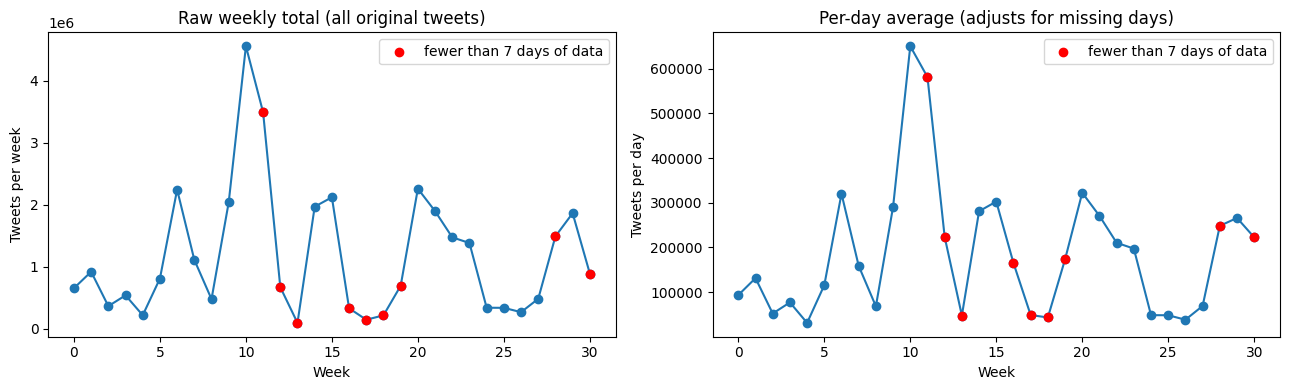

In [ ]:
weekly = vol[["week", "days_with_data", "weekly_orig_total", "weekly_orig_per_day"]].drop_duplicates()
is_partial = weekly["days_with_data"] < 7

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(weekly["week"], weekly["weekly_orig_total"], marker="o")
axes[0].scatter(weekly.loc[is_partial, "week"], weekly.loc[is_partial, "weekly_orig_total"],
                color="red", zorder=3, label="fewer than 7 days of data")
axes[0].set_title("Raw weekly total (all original tweets)")
axes[0].set_xlabel("Week")
axes[0].set_ylabel("Tweets per week")
axes[0].legend()

axes[1].plot(weekly["week"], weekly["weekly_orig_per_day"], marker="o")
axes[1].scatter(weekly.loc[is_partial, "week"], weekly.loc[is_partial, "weekly_orig_per_day"],
                color="red", zorder=3, label="fewer than 7 days of data")
axes[1].set_title("Per-day average (adjusts for missing days)")
axes[1].set_xlabel("Week")
axes[1].set_ylabel("Tweets per day")
axes[1].legend()

plt.tight_layout()
plt.show()

**Chart 2** shows each issue's estimated tweets per day. The y-axis is on a log scale so small issues (like abortion) are still visible next to big ones.

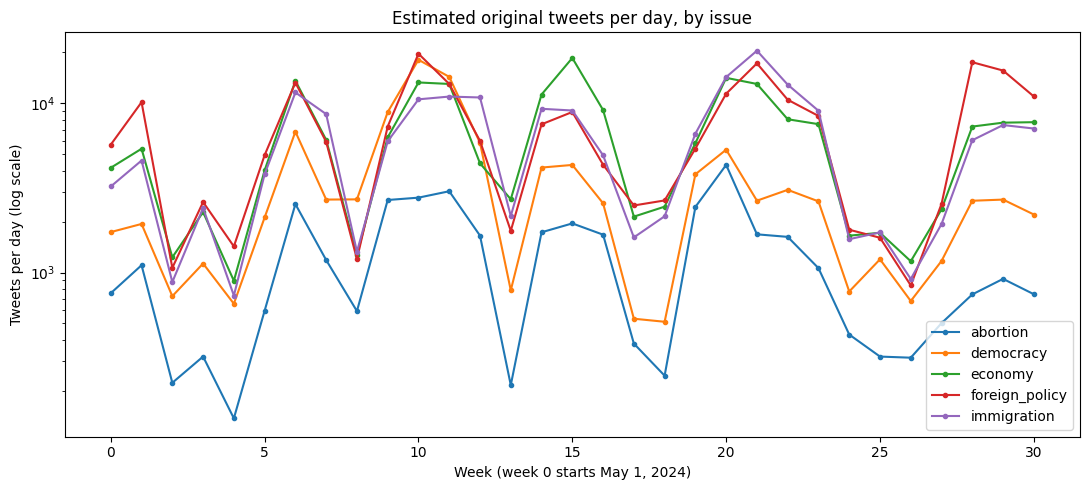

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5))

for issue_name, rows in vol.groupby("issue"):
    ax.plot(rows["week"], rows["orig_per_day"], marker="o", markersize=3, label=issue_name)

ax.set_yscale("log")
ax.set_title("Estimated original tweets per day, by issue")
ax.set_xlabel("Week (week 0 starts May 1, 2024)")
ax.set_ylabel("Tweets per day (log scale)")
ax.legend()
plt.tight_layout()
plt.show()

#### Does volume relate to the shift score?
**Spearman rank correlation** (ρ, "rho") checks whether two things rise and fall together, using their rank order instead of raw values. It runs from −1 to +1. A negative ρ means: when volume is low, the shift score tends to be high.

We look at 3 volume measures:
- **Sample tweets** (`n_tweets_issue`): how many tweets the shift score was actually computed from. A strong negative ρ here points to **noise** (small samples look like they "shifted" by chance). That's what the noise floor is for.
- **Estimated real volume** (`log_orig_per_day`): estimated volume in the full datase.
- **Change in estimated volume** (`log_orig_per_day_change`): how much louder or quieter the issue was than the week before. Positive means more tweets per day than last week; negative means fewer.

This is a check that helps explain ablation results later.

In [ ]:
# Only rows that have a shift score (each issue's first week has none)
has_shift = vol.dropna(subset=["shift_score"])

for col in ["n_tweets_issue", "log_orig_per_day", "log_orig_per_day_change"]:
    rows = has_shift.dropna(subset=[col])
    rho, p = spearmanr(rows[col], rows["shift_score"])
    print(f"{col:26s} vs shift_score: rho = {rho:+.2f}  (p = {p:.3g}, n = {len(rows)})")

n_tweets_issue             vs shift_score: rho = -0.60  (p = 3.78e-16, n = 149)
log_orig_per_day           vs shift_score: rho = -0.37  (p = 3.56e-06, n = 149)
log_orig_per_day_change    vs shift_score: rho = -0.14  (p = 0.0936, n = 149)


## Save
- `volume_summary.csv`: just the keys and volume columns (small and easy to join on `week` + `issue`)
- `features_with_volume.csv`: Tanisha's full table plus the volume columns, ready to load in the supervised pipeline

In [ ]:
volume_cols = ["week", "week_start", "issue", "days_with_data",
               "weekly_orig_total", "weekly_orig_per_day",
               "issue_share", "orig_tweet_count", "orig_per_day",
               "log_orig_per_day", "log_orig_per_day_change"]

volume_summary = vol[volume_cols].sort_values(["issue", "week"])
volume_summary.to_csv(VOLUME_OUT, index=False)

# Full table: put rows back in Tanisha's original order (by issue, then week)
features_with_volume = vol.sort_values(["issue", "week"])
features_with_volume.to_csv(FEATURES_OUT, index=False)

print("Saved", VOLUME_OUT, volume_summary.shape)
print("Saved", FEATURES_OUT, features_with_volume.shape)

Saved ../DataFiles/volume_summary.csv (155, 11)
Saved ../DataFiles/features_with_volume.csv (155, 26)


## Findings

**Estimated volume by issue.** Foreign policy had the most estimated original tweets per day on average (about 7,200), followed by economy (about 6,500), immigration (about 6,300), democracy (about 3,500), and abortion (about 1,250). Together, the 5 issues make up 8–20% of each week's sample, so most tweets are not about any of these issues.

**Partial weeks.** 9 of 31 weeks have tweets on fewer than 7 days. Dividing by days_with_data brings weeks 12 and 16 back to normal levels. Weeks 13, 17, and 18 are still among the lowest weeks even per day, so fewer days does not fully explain their low totals.

**Volume and the shift score.** The shift score is higher when an issue has fewer tweets:
- Sample tweets (`n_tweets_issue`): ρ = −0.60 (strong)
- Estimated volume (`log_orig_per_day`): ρ = −0.37 (moderate)
- Change in estimated volume (`log_orig_per_day_change`): ρ = −0.14 (weak, not statistically significant, p = 0.09)

The link is strongest with the number of sample tweets, which is what the shift score is calculated from. This suggests that part of the shift score reflects small-sample noise rather than narrative drift, which supports subtracting the noise floor.

**What this means for the ablation study.** Because the shift score is partly tied to volume, the volume-only model and the topic model share some of the same information. The gain from adding topic features may be smaller than it would be if the two were unrelated.

## Notes

**Suggested "Group A: volume only" features for the ablation study**
- `log_orig_per_day`: how loud the issue is (log scale, adjusted for missing days)
- `log_orig_per_day_change`: how much louder or quieter than last week
- `issue_share`: the issue's share of the week's conversation

Use the **per-day** versions in models, not raw `orig_tweet_count`, so weeks with fewer days of data don't look like weeks with less discussion. Keep `orig_tweet_count` for tables and charts, since it's easier to read.

**Limitations to state in the Feature Engineering section**
- Volume is an estimate (full weekly total × sample share), not a count.
- Small issues (abortion: about 45-120 (usually 70-120) sample tweets a week) have less precise shares.
- Several weeks have fewer than 7 days of data (see the partial-weeks table above). Per-day volume corrects the level, but those weeks are still based on fewer days, so they are less certain. Week 30 is short because our data ends on Nov 30.
- Issues are tagged by keyword, and a tweet can match more than one issue, so issue volumes can overlap.